# Task 2: Feature Selection & Importance Evaluation

## 1. Introduction

The goal of this task is to identify the most important features associated with employee attrition using different feature selection and importance evaluation techniques.

The analysis uses the following methods:

- **Correlation Analysis:** To examine the linear relationships between features and employee attrition.
- **Recursive Feature Elimination (RFE):** To select a subset of features based on a machine learning model.
- **Permutation Importance:** To evaluate how much each feature contributes to the model's predictive performance.

The target variable is `Attrition`, which indicates whether an employee has left the company. The results of these techniques will be compared to identify the most relevant features and discuss their expected impact on model performance.

In [5]:
import pandas as pd

url = "https://raw.githubusercontent.com/nhahub/NHA-5-153/main/employee_attriton_data_clean.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset shape: (49000, 8)
Columns: ['EmployeeID', 'Age', 'Gender', 'JobRole', 'TenureYears', 'PerformanceRating', 'MonthlySalary', 'Attrition']


,EmployeeID,Age,Gender,JobRole,TenureYears,PerformanceRating,MonthlySalary,Attrition
0,23056,33.0,Female,Manager,1.0,1.0,9734.51,No
1,47703,33.0,Female,HR Specialist,5.0,4.0,7552.38,No
2,7424,45.0,Male,Manager,0.0,4.0,3931.63,No
3,34697,35.0,Non-Binary,Manager,2.0,3.0,7992.26,No
4,31490,42.0,Male,Manager,1.0,3.0,5215.60,Yes


In [7]:
print("Dataset shape:", df.shape)
df.info()
print("\nMissing values:")
print(df.isnull().sum())
print("\nAttrition values:")
print(df["Attrition"].value_counts(dropna=False))

Dataset shape: (49000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49000 entries, 0 to 48999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   EmployeeID         49000 non-null  int64  
 1   Age                49000 non-null  float64
 2   Gender             49000 non-null  object 
 3   JobRole            49000 non-null  object 
 4   TenureYears        49000 non-null  float64
 5   PerformanceRating  49000 non-null  float64
 6   MonthlySalary      49000 non-null  float64
 7   Attrition          49000 non-null  object 
dtypes: float64(4), int64(1), object(3)
memory usage: 3.0+ MB

Missing values:
EmployeeID           0
Age                  0
Gender               0
JobRole              0
TenureYears          0
PerformanceRating    0
MonthlySalary        0
Attrition            0
dtype: int64

Attrition values:
Attrition
No     36470
Yes    12530
Name: count, dtype: int64


In [8]:
df_corr = df.copy()
print(df_corr["Attrition"].unique())

['No' 'Yes']


Correlation with Attrition:


,Attrition
TenureYears,-0.112733
PerformanceRating,0.046575
MonthlySalary,-0.045422
Age,-0.006474
Gender_Non-Binary,0.004499
Gender_Male,-0.002479
JobRole_HR Specialist,0.001767
JobRole_Manager,-0.000578
JobRole_Sales Exec,0.000294
JobRole_Software Engineer,0.000154


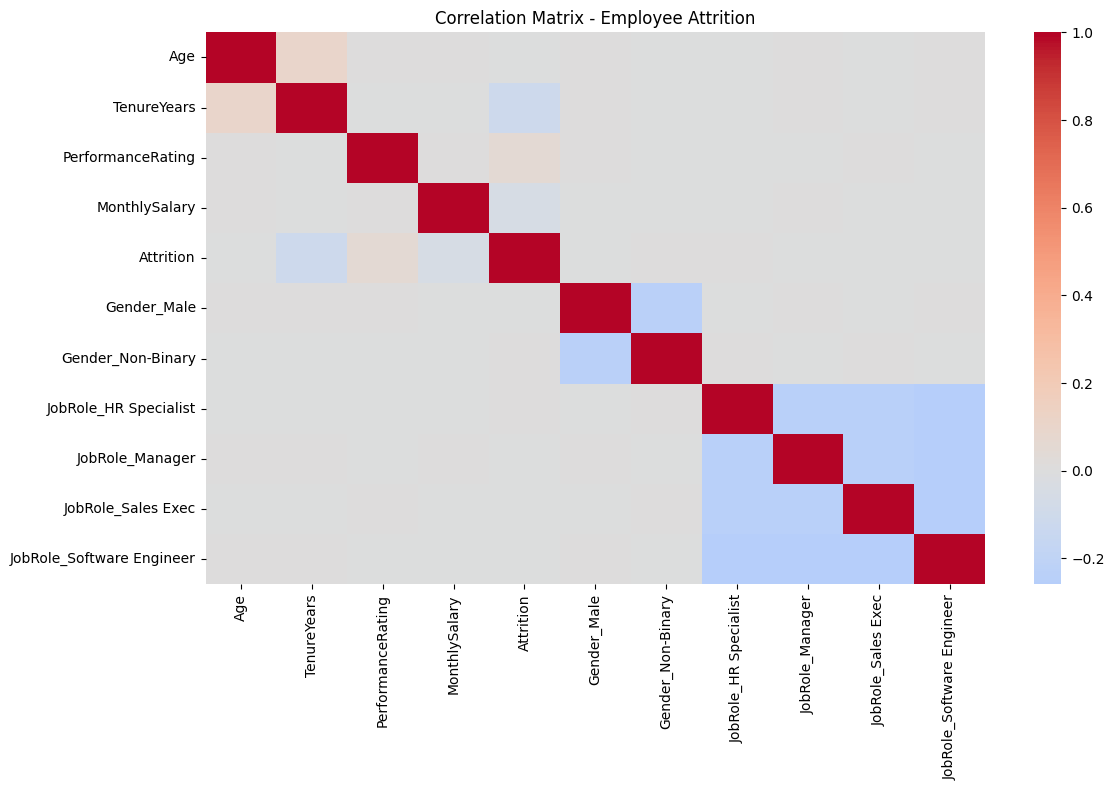

In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Make a copy so we don't change the original dataset
df_corr = df.copy()

# 2. Convert the target column into numbers
df_corr["Attrition"] = df_corr["Attrition"].map({
    "No": 0,
    "Yes": 1
})

# 3. Remove EmployeeID because it is only an identifier
df_corr = df_corr.drop(columns=["EmployeeID"])

# 4. Convert categorical columns into numeric columns
df_corr = pd.get_dummies(
    df_corr,
    columns=["Gender", "JobRole"],
    drop_first=True,
    dtype=int
)

# 5. Calculate the correlation matrix
corr_matrix = df_corr.corr()

# 6. Display correlations with Attrition
attrition_corr = corr_matrix["Attrition"].drop("Attrition")
attrition_corr = attrition_corr.sort_values(
    key=abs,
    ascending=False
)

print("Correlation with Attrition:")
display(attrition_corr.to_frame())

# 7. Visualize the correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix - Employee Attrition")
plt.tight_layout()
plt.show()


In [10]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.metrics import roc_auc_score, f1_score

# Prepare the target and features
df_model = df.copy()
df_model["Attrition"] = df_model["Attrition"].map({
    "No": 0,
    "Yes": 1
})

X = df_model.drop(
    columns=["Attrition", "EmployeeID"]
)
y = df_model["Attrition"]

# Identify numerical and categorical features
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

# Preprocess numerical features
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()

# Select half of the encoded features using RFE
n_features = max(1, X_train_processed.shape[1] // 2)

rfe = RFE(
    estimator=LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    n_features_to_select=n_features
)

rfe.fit(X_train_processed, y_train)

# Display feature selection results
rfe_results = pd.DataFrame({
    "Feature": feature_names,
    "Selected": rfe.support_,
    "Ranking": rfe.ranking_
}).sort_values(
    ["Selected", "Ranking"],
    ascending=[False, True]
)

display(rfe_results)


,Feature,Selected,Ranking
1,num__TenureYears,True,1
2,num__PerformanceRating,True,1
3,num__MonthlySalary,True,1
4,cat__Gender_Female,True,1
5,cat__Gender_Male,True,1
6,cat__Gender_Non-Binary,True,1
7,cat__JobRole_Data Analyst,False,2
0,num__Age,False,3
9,cat__JobRole_Manager,False,4
10,cat__JobRole_Sales Exec,False,5


ROC-AUC: 0.5768
F1-score: 0.402


,Feature,Importance,Std
3,TenureYears,0.057523,0.001597
5,MonthlySalary,0.012134,0.000619
4,PerformanceRating,0.012068,0.002008
2,JobRole,-0.000004,0.000095
0,Age,-0.000116,0.000448
1,Gender,-0.000388,0.000524


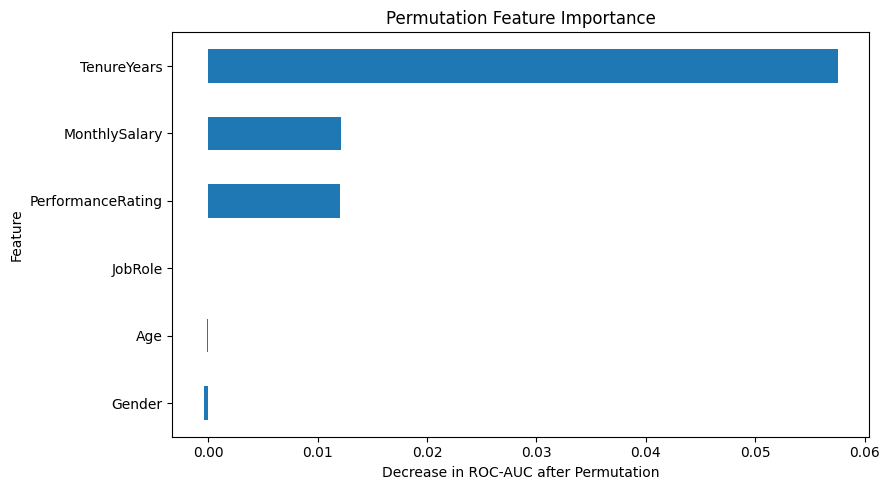

In [11]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Build a complete model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

# Train the model
model.fit(X_train, y_train)

# Evaluate model performance
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

# Calculate permutation importance
perm = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create the results table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df)

# Plot the results
importance_df.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 5)
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in ROC-AUC after Permutation")
plt.tight_layout()
plt.show()


# Task 2: Feature Selection & Importance Evaluation

## 1. Objective
The objective of this task is to identify the most relevant features for predicting employee attrition using correlation analysis, Recursive Feature Elimination (RFE), and permutation importance.

## 2. Correlation Analysis
The correlation analysis showed that `TenureYears` had the strongest linear correlation with attrition, with a coefficient of -0.1127. `PerformanceRating` and `MonthlySalary` had weak correlations of 0.0466 and -0.0454, respectively. The remaining features had correlations close to zero.

These results indicate that the linear relationships between the available features and attrition are generally weak.

## 3. Recursive Feature Elimination (RFE)
RFE selected six encoded features: `TenureYears`, `PerformanceRating`, `MonthlySalary`, and the three encoded gender categories. The remaining encoded features were not selected in the chosen subset.

RFE provides a model-based feature selection result. Selection does not necessarily mean that a feature has a strong individual effect on attrition.

## 4. Permutation Importance
Permutation importance was evaluated using ROC-AUC as the scoring metric.

| Feature | Importance |
|---|---:|
| TenureYears | 0.057523 |
| MonthlySalary | 0.012134 |
| PerformanceRating | 0.012068 |
| JobRole | -0.000004 |
| Age | -0.000116 |
| Gender | -0.000388 |

`TenureYears` was the most important feature because shuffling its values caused the largest decrease in model performance. `MonthlySalary` and `PerformanceRating` had smaller positive importance values. `JobRole`, `Age`, and `Gender` showed importance values close to zero.

## 5. Model Evaluation
The baseline Logistic Regression model achieved a ROC-AUC of 0.5768 and an F1-score of 0.402 on the test set.

These results indicate limited discrimination between employees who leave and those who stay. Therefore, the selected features should be evaluated further, and model performance should be compared before and after feature selection.

## 6. Selected Features and Expected Impact

| Feature | Evidence | Expected Impact |
|---|---|---|
| TenureYears | Highest permutation importance and strongest correlation | Likely to provide the greatest contribution to predictions in the current model |
| MonthlySalary | Positive permutation importance; weak correlation | May provide additional predictive information |
| PerformanceRating | Positive permutation importance; weak correlation | May provide additional predictive information |
| Gender | Near-zero permutation importance | May provide little additional predictive value in the current model |
| Age | Near-zero permutation importance and not selected by RFE | May provide little additional predictive value in the current model |
| JobRole | Near-zero permutation importance; most encoded categories were not selected by RFE | May provide little additional predictive value in the current model |

## 7. Conclusion
The three techniques consistently suggest that `TenureYears` deserves further attention as a potential predictor of employee attrition. `MonthlySalary` and `PerformanceRating` may also contribute to prediction, although their importance is considerably lower.

However, the baseline model achieved a ROC-AUC of 0.5768, indicating limited predictive performance. The findings describe predictive associations and do not establish causal relationships. Further evaluation using the same train-test split is required to determine whether feature selection improves model performance.